# ML Assignment 2 — Online Shoppers Purchasing Intention

**Programme:** BITS Pilani WILP, M.Tech (AIML), Machine Learning
**Task:** Train five classifiers on one public dataset, evaluate them with six metrics, save the models for a Streamlit app.

**Dataset:** [Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
(UCI Machine Learning Repository, id 468, licence CC BY 4.0). Each row is one browsing session on an
e-commerce site; the target `Revenue` says whether the session ended in a purchase.

Notebook sections:
1. Load and inspect the data
2. Train / test split and preprocessing design
3. Train, tune and evaluate the five classifiers
4. Comparison and observations


## 1. Load and inspect the data

The raw CSV is committed under `data/` so this notebook runs without internet access (for example on BITS Virtual Lab).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42
DATA_PATH = Path("data") / "online_shoppers_intention.csv"
RESULTS_DIR = Path("results")
MODEL_DIR = Path("model")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

python       3.12.13
numpy        2.5.4
pandas       3.1.0
scikit-learn 1.9.1
matplotlib   3.11.2
seaborn      0.13.2


In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"rows = {raw.shape[0]:,}   columns = {raw.shape[1]}")
raw.head()

rows = 12,330   columns = 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

### Column groups

| Group | Columns | Meaning |
|---|---|---|
| Page counts | `Administrative`, `Informational`, `ProductRelated` | number of pages of each type visited in the session |
| Page durations | `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | seconds spent on each page type |
| Google Analytics metrics | `BounceRates`, `ExitRates`, `PageValues` | averages over the pages visited in the session |
| Calendar | `SpecialDay`, `Month`, `Weekend` | closeness to a special day (0–1), month of the visit, weekend flag |
| Visitor / technical | `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType` | integer-coded categories and visitor type |
| **Target** | `Revenue` | `True` if the session ended with a transaction |

The integer-coded columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are category labels, not
quantities, so they will be treated as categorical features in the next section.

In [4]:
TARGET = "Revenue"
NUMERIC_FEATURES = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICAL_FEATURES = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

assert set(FEATURES) | {TARGET} == set(raw.columns), "column list does not match the file"
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {len(FEATURES)} input features")

10 numeric + 7 categorical = 17 input features


### Data quality checks

In [5]:
missing = raw.isna().sum()
print("missing values per column:")
print(missing[missing > 0] if missing.any() else "  none")

n_dup = raw.duplicated().sum()
print(f"\nexact duplicate rows: {n_dup}  ({n_dup / len(raw):.2%})")
print("Duplicates are kept: the file has no session id, and sessions that bounce on a single page")
print("legitimately produce identical rows, so they are treated as genuine observations.")

missing values per column:
  none

exact duplicate rows: 125  (1.01%)
Duplicates are kept: the file has no session id, and sessions that bounce on a single page
legitimately produce identical rows, so they are treated as genuine observations.


         sessions  percent
Revenue                   
False       10422    84.53
True         1908    15.47


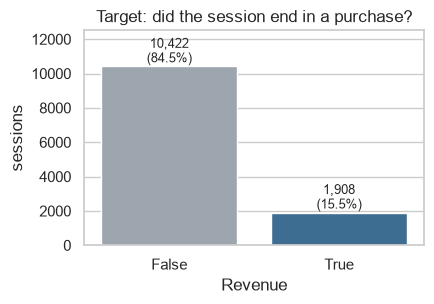

In [6]:
target_counts = raw[TARGET].value_counts()
target_pct = raw[TARGET].value_counts(normalize=True).mul(100).round(2)
target_table = pd.DataFrame({"sessions": target_counts, "percent": target_pct})
print(target_table)

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.barplot(x=target_table.index.astype(str), y=target_table["sessions"], hue=target_table.index.astype(str),
            palette=["#9aa5b1", "#2f6f9f"], legend=False, ax=ax)
for i, v in enumerate(target_table["sessions"]):
    ax.text(i, v, f"{v:,}\n({target_table['percent'].iloc[i]:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set(title="Target: did the session end in a purchase?", xlabel="Revenue", ylabel="sessions")
ax.set_ylim(0, target_table["sessions"].max() * 1.2)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "target_distribution.png", dpi=120)
plt.show()

The classes are imbalanced: only about one session in six converts. Plain accuracy is therefore a weak
yardstick (always predicting "no purchase" scores about 85 %). The AUC, F1 and especially the Matthews
Correlation Coefficient will be the metrics to watch when the models are compared.

In [7]:
raw[NUMERIC_FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


In [8]:
for col in CATEGORICAL_FEATURES:
    vc = raw[col].value_counts()
    top = ", ".join(f"{k}: {int(v):,}" for k, v in vc.head(6).items())
    print(f"{col:17s} {vc.size:2d} levels  ->  {top}{', ...' if vc.size > 6 else ''}")

Month             10 levels  ->  May: 3,364, Nov: 2,998, Mar: 1,907, Dec: 1,727, Oct: 549, Sep: 448, ...
OperatingSystems   8 levels  ->  2: 6,601, 1: 2,585, 3: 2,555, 4: 478, 8: 79, 6: 19, ...
Browser           13 levels  ->  2: 7,961, 1: 2,462, 4: 736, 5: 467, 6: 174, 10: 163, ...
Region             9 levels  ->  1: 4,780, 3: 2,403, 4: 1,182, 2: 1,136, 6: 805, 7: 761, ...
TrafficType       20 levels  ->  2: 3,913, 1: 2,451, 3: 2,052, 4: 1,069, 13: 738, 10: 450, ...
VisitorType        3 levels  ->  Returning_Visitor: 10,551, New_Visitor: 1,694, Other: 85
Weekend            2 levels  ->  False: 9,462, True: 2,868


### Numeric feature distributions

Most numeric features are heavily right-skewed (many zero-valued sessions, a long tail of long sessions),
which is why the pipelines in the next section standardise them before the distance-based and linear models.

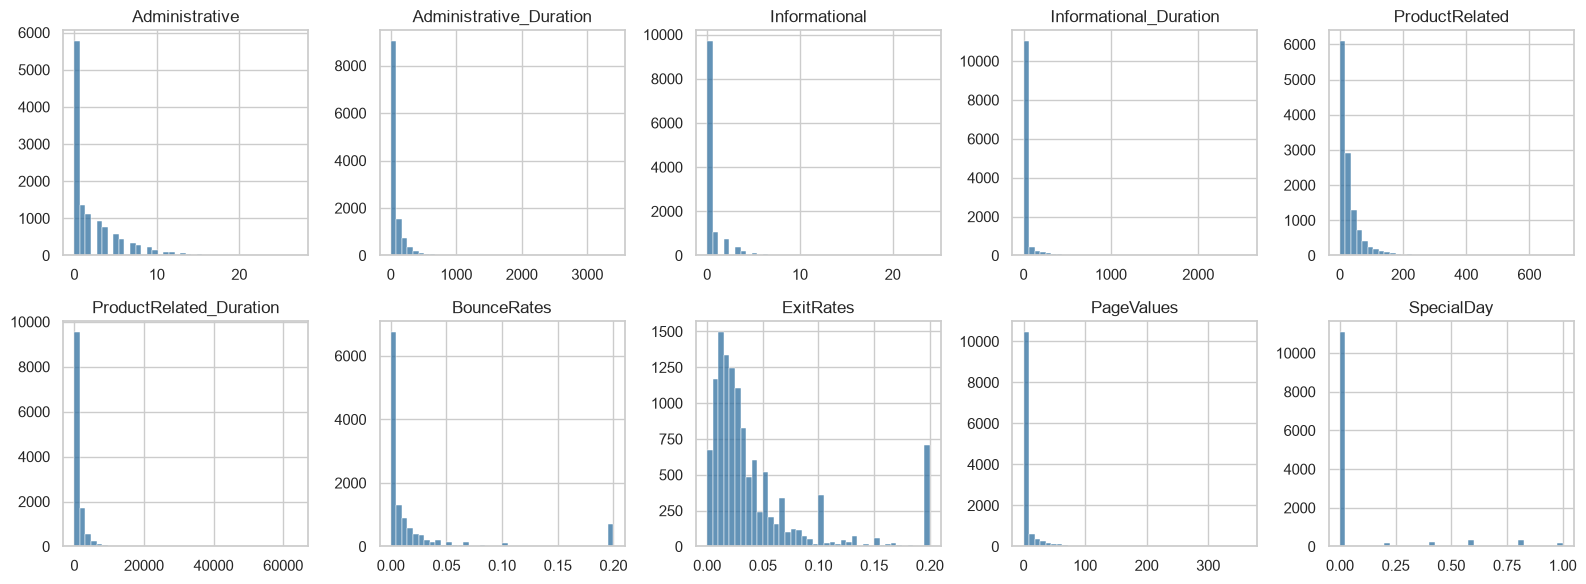

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(raw[col], bins=40, ax=ax, color="#2f6f9f", edgecolor=None)
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "numeric_distributions.png", dpi=120)
plt.show()

In [10]:
conv_by_visitor = raw.groupby("VisitorType")[TARGET].mean().mul(100).round(2)
conv_by_month = raw.groupby("Month")[TARGET].mean().mul(100).round(2).sort_values(ascending=False)
print("conversion rate (%) by visitor type:\n", conv_by_visitor.to_string(), "\n")
print("conversion rate (%) by month:\n", conv_by_month.to_string())

conversion rate (%) by visitor type:
 VisitorType
New_Visitor          24.91
Other                18.82
Returning_Visitor    13.93 

conversion rate (%) by month:
 Month
Nov     25.35
Oct     20.95
Sep     19.20
Aug     17.55
Jul     15.28
Dec     12.51
May     10.85
June    10.07
Mar     10.07
Feb      1.63


### Assignment constraints check

The assignment requires at least 12 input features and at least 500 instances.

In [11]:
MIN_FEATURES, MIN_ROWS = 12, 500
assert len(FEATURES) >= MIN_FEATURES, f"need >= {MIN_FEATURES} features, got {len(FEATURES)}"
assert len(raw) >= MIN_ROWS, f"need >= {MIN_ROWS} rows, got {len(raw)}"

profile_lines = [
    "Online Shoppers Purchasing Intention (UCI id 468)",
    f"rows: {len(raw)}",
    f"input features: {len(FEATURES)} ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)",
    f"target: {TARGET} (binary)",
    f"positive class (Revenue=True): {int(target_counts.get(True, 0))} ({target_pct.get(True, 0):.2f}%)",
    f"negative class (Revenue=False): {int(target_counts.get(False, 0))} ({target_pct.get(False, 0):.2f}%)",
    f"missing values: {int(missing.sum())}",
    f"exact duplicate rows (kept): {int(n_dup)}",
    f"constraint check: features >= {MIN_FEATURES} and rows >= {MIN_ROWS} -> PASS",
]
(RESULTS_DIR / "data_profile.txt").write_text("\n".join(profile_lines) + "\n")
print("\n".join(profile_lines))

Online Shoppers Purchasing Intention (UCI id 468)
rows: 12330
input features: 17 (10 numeric, 7 categorical)
target: Revenue (binary)
positive class (Revenue=True): 1908 (15.47%)
negative class (Revenue=False): 10422 (84.53%)
missing values: 0
exact duplicate rows (kept): 125
constraint check: features >= 12 and rows >= 500 -> PASS


## 2. Train / test split and preprocessing design

**Split.** 80 % of the sessions are used for training (including cross-validated tuning) and 20 % are held
out as the test set. The split is *stratified* on `Revenue` so both parts keep the same 15 % purchase rate,
and `random_state=42` makes it reproducible. The held-out part is written to `test_data.csv` with the raw
feature columns plus the target, exactly as the Streamlit app expects an upload.

**Preprocessing.** One `ColumnTransformer` handles both column groups:

| Columns | Transformer | Why |
|---|---|---|
| 10 numeric | `StandardScaler` | KNN and SVM are distance-based and logistic regression is scale-sensitive; the skewed durations would otherwise dominate |
| 7 categorical | `OneHotEncoder(handle_unknown="ignore")` | integer codes such as `Browser=2` are labels, not quantities; unseen levels in an upload become all-zero instead of raising |

The transformer is **fit on the training split only** and lives inside each model's `Pipeline`, so test
statistics never leak into the fitted scaler or encoder, and the saved pipeline accepts a raw CSV directly.
Scaling is a monotone transform, so it is harmless for the decision tree.

In [12]:
import json
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = raw[FEATURES]
y = raw[TARGET].astype(int)          # True/False -> 1/0 (1 = purchase, the positive class)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "positive": [int(y_train.sum()), int(y_test.sum())],
    "positive_rate_%": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["train", "test"])
print(split_summary)

       rows  positive  positive_rate_%
train  9864      1526            15.47
test   2466       382            15.49


In [13]:
# Held-out test set, saved with raw features + target for the Streamlit app and the repo.
test_df = X_test.copy()
test_df[TARGET] = raw.loc[X_test.index, TARGET]   # keep the original True/False values
test_df.to_csv("test_data.csv", index=False)
print(f"test_data.csv written: {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")

# Feature schema: lets the app validate an uploaded CSV before scoring it.
schema = {
    "target": TARGET,
    "positive_label": True,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "categorical_levels": {c: sorted(map(str, raw[c].unique())) for c in CATEGORICAL_FEATURES},
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(MODEL_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=2))
print("model/feature_schema.json written")

test_data.csv written: 2,466 rows x 18 columns
model/feature_schema.json written


In [14]:
def make_preprocessor():
    """Fresh, unfitted preprocessing step (one instance per model pipeline)."""
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

prep = make_preprocessor().fit(X_train)
n_out = len(prep.get_feature_names_out())
print(f"preprocessed feature count: {len(NUMERIC_FEATURES)} scaled numeric + "
      f"{n_out - len(NUMERIC_FEATURES)} one-hot columns = {n_out}")

preprocessed feature count: 10 scaled numeric + 65 one-hot columns = 75


### Validation of the split and preprocessing

Checks that must hold before any model is trained:

1. `test_data.csv` reloads with the same dtypes and values as the in-memory test split.
2. Transforming the reloaded test file with the preprocessor fitted on train yields no NaN and the expected column count.
3. Train and test keep the same purchase rate (stratification worked) and share no rows.

In [15]:
reloaded = pd.read_csv("test_data.csv")
X_reloaded, y_reloaded = reloaded[FEATURES], reloaded[TARGET].astype(int)

# 1. round trip through CSV is lossless
assert list(reloaded.columns) == FEATURES + [TARGET], "column order changed"
assert X_reloaded.dtypes.equals(X_train.dtypes), "dtypes changed after CSV round trip"
pd.testing.assert_frame_equal(X_reloaded, X_test.reset_index(drop=True))
assert (y_reloaded.values == y_test.values).all()

# 2. preprocessing of the reloaded file
Xt = prep.transform(X_reloaded)
assert Xt.shape == (len(reloaded), n_out), Xt.shape
assert not np.isnan(Xt).any(), "NaN after preprocessing"
assert np.allclose(Xt[:, :len(NUMERIC_FEATURES)].mean(0), 0, atol=0.15), "scaled numerics drifted"

# 3. stratification and disjointness
assert abs(y_train.mean() - y_test.mean()) < 0.005, "class balance differs between train and test"
assert X_train.index.intersection(X_test.index).empty, "train/test overlap"
assert len(X_train) + len(X_test) == len(raw)

print("all split/preprocessing checks passed")
print(f"train {len(X_train):,} rows | test {len(X_test):,} rows | {n_out} model inputs")

all split/preprocessing checks passed
train 9,864 rows | test 2,466 rows | 75 model inputs
